In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

# 1. Chuẩn bị môi trường

In [6]:
ENV_ID = "CartPole-v1"
SEED = 1
EVALUTE_SEED = 1806

NUM_ACTIONS = 2
np.set_printoptions(precision=4, suppress=True)

def make_env(env_id = ENV_ID, **kwargs):
	return gym.make(env_id, **kwargs)

In [7]:
env = make_env()
core = env.unwrapped

print(core.observation_space)
print(core.action_space)
print(f"The maximum position allowed: {core.x_threshold}")
print(f"The maximum angle allowed: {core.theta_threshold_radians}")
print(f"The maximum number of steps: {env.spec.max_episode_steps}")

Box([-4.8       -inf -0.4189    -inf], [4.8       inf 0.4189    inf], (4,), float32)
Discrete(2)
The maximum position allowed: 2.4
The maximum angle allowed: 0.20943951023931953
The maximum number of steps: 500


## 1.1. Chuẩn bị hàm run episode và hàm đánh giá policy

In [8]:
def run_episode(env, policy, seed):
	rng = np.random.default_rng(seed=seed)
	obs, _ = env.reset(seed=seed)
	start = obs.copy()
	steps = 0
	while True:
		obs, reward, terminated, truncated, _ = env.step(policy(obs, rng))
		steps += 1
		if terminated or truncated:
			return start, steps, terminated

def evaluate(policy, n_episodes=500, seed=EVALUTE_SEED, env_kwargs=None):
	env = make_env(ENV_ID, **(env_kwargs or {}))
	seeds = seed + np.arange(n_episodes)
	runs = [run_episode(env, policy, int(seed)) for seed in seeds]
	env.close()

	return {
		"seeds": seeds,
		"starts": np.array([r[0] for r in runs]),
		"returns": np.array([r[1] for r in runs], dtype=float),
		"terminated": np.array([r[2] for r in runs]),
	}

# 1.2. Chuẩn bị chiến lược ngẫu nhiên và chiến lược theo/ngược dấu góc

In [9]:
def random_policy(obs, rng) -> int:
	action = rng.integers(NUM_ACTIONS)
	return action

def angle_policy(obs, rng) -> int:
	return int(obs[2] >= 0)

def reverse_angle_policy(obs, rng) -> int:
	return int(obs[2] < 0)

# 1.3. Chuẩn bị hàm vẽ box plot

In [71]:
def draw_box_plots(returns, strategies):
	fig, ax = plt.subplots(figsize=(10, 7))
	ax.boxplot(returns, tick_labels=strategies)

# 1.4. Thử nghiệm với các chiến lược

In [11]:
def test_policy(policy, seed):
	env = make_env(render_mode="human")
	obs, _ = env.reset(seed=seed)
	rng = np.random.default_rng(seed=seed)
	total_reward = 0
	while True:
		action = policy(obs, rng)
		nxt_obs, reward, terminated, truncated, _ = env.step(action)
		obs = nxt_obs
		total_reward += 1
		if terminated or truncated:
			break
	print(f"Episode finished! Total reward: {total_reward}")
	env.close()

In [12]:
policies = {
	"random": random_policy,
	"angle_strategy": angle_policy,
	"reverse_angle_strategy": reverse_angle_policy,
}

records = np.array([evaluate(policy)["returns"] for name, policy in policies.items()])
names = np.array([key for key in policies.keys()])

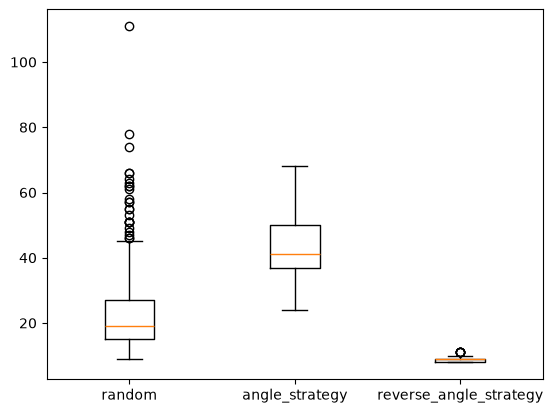

In [13]:
draw_box_plots(records.T, names)


In [14]:
test_policy(angle_policy, 2)

Episode finished! Total reward: 35


# 2. Rời rạc hóa dữ liệu

In [17]:
X_MAX = core.x_threshold
X_VELO_MAX = 2
THETA_MAX = core.theta_threshold_radians
THETA_VELO_MAX = 2
print(X_MAX)
print(THETA_MAX)

THRESHOLDS = [X_MAX, X_VELO_MAX, THETA_MAX, THETA_VELO_MAX]
NUM_CUTS = [6, 6, 6, 6]
CUTS = [[-THRESHOLDS[i] + THRESHOLDS[i] * 2 / (NUM_CUTS[i] + 1) * (j + 1) for j in range(NUM_CUTS[i])] for i in range(len(NUM_CUTS))]
LIMITS = [(-threshold, threshold) for threshold in THRESHOLDS]
print(CUTS)
print(LIMITS)

def num_bins(cuts):
	return tuple(len(c) + 1 for c in cuts)

def bin_indices(obs, cuts):
	return tuple(int(np.searchsorted(cut, x, side="right")) for x, cut in zip(obs, cuts))

def get_index(obs, cuts):
	return int(np.ravel_multi_index(bin_indices(obs, cuts), num_bins(cuts)))

def get_state_label(index, cuts):
	return tuple(int(pos) for pos in np.unravel_index(index, num_bins(cuts)))

NUM_STATES = int(np.prod(num_bins(CUTS)))
print(f"The number of states (except for the terminated state): {NUM_STATES}")
TERMINATED_STATE = NUM_STATES

# assert get_index([1, -2.0, -2.0, -2.0], CUTS) == 2 * 4 * 4 * 4

2.4
0.20943951023931953
[[-1.7142857142857142, -1.0285714285714285, -0.34285714285714297, 0.34285714285714297, 1.028571428571429, 1.714285714285714], [-1.4285714285714286, -0.8571428571428572, -0.2857142857142858, 0.2857142857142856, 0.8571428571428568, 1.4285714285714284], [-0.1495996501709425, -0.08975979010256552, -0.029919930034188497, 0.029919930034188497, 0.08975979010256549, 0.14959965017094254], [-1.4285714285714286, -0.8571428571428572, -0.2857142857142858, 0.2857142857142856, 0.8571428571428568, 1.4285714285714284]]
[(-2.4, 2.4), (-2, 2), (-0.20943951023931953, 0.20943951023931953), (-2, 2)]
The number of states (except for the terminated state): 2401


In [18]:
def cell_box(state, cuts, limits):
	low, high = np.empty(4), np.empty(4)
	for i, pos in enumerate(get_state_label(state, cuts)):
		edges = np.r_[limits[i][0], cuts[i], limits[i][1]]
		low[i], high[i] = edges[pos], edges[pos + 1]
	return low, high

def simulate_state(sim, state, action):
	sim.state = state
	sim.steps_beyond_terminated = None
	obs, reward, terminated, truncated, _ = sim.step(action)
	return obs, reward, terminated

def build_simulated_mdp_tabular(cuts, limits, num_samples, seed, env_kwargs=None):
	num_states = int(np.prod(num_bins(cuts)))
	terminated_state = num_states

	sim = make_env(ENV_ID, **(env_kwargs or {})).unwrapped
	sim.reset(seed=seed)
	rng = np.random.default_rng(seed=seed)

	sum_rewards = np.zeros((num_states, NUM_ACTIONS))
	counts = [[defaultdict(float) for j in range(NUM_ACTIONS)] for i in range(num_states)]

	for state in range(num_states):
		low, high = cell_box(state, cuts, limits)
		samples = rng.uniform(low, high, size=(num_samples, 4))
		for action in range(NUM_ACTIONS):
			for obs in samples:
				nxt_obs, reward, terminated = simulate_state(sim, obs, action)
				sum_rewards[state, action] += reward
				counts[state][action][terminated_state if terminated else get_index(nxt_obs, cuts)] += 1
	sim.close()
	for state in range(num_states):
		for action in range(NUM_ACTIONS):
			for nxt_state in counts[state][action].keys():
				counts[state][action][nxt_state] /= num_samples
	sum_rewards /= num_samples
	return sum_rewards, counts

In [19]:
NUM_SAMPLES = 500
sum_rewards, prob = build_simulated_mdp_tabular(CUTS, LIMITS, NUM_SAMPLES, SEED)

In [20]:
assert np.allclose(sum_rewards, 1.0)
for state in range(NUM_STATES):
	for action in range(NUM_ACTIONS):
		sum_p = 0.
		for nxt_state, p in prob[state][action].items():
			sum_p += p
			assert p > 0.
		assert np.allclose(sum_p, 1.0)

# 3. Policy iteration

## 3.1. Policy evaluation

In [21]:
def bellman_pi(v, pi, prob, reward, gamma):
	v_new = np.zeros(v.shape[0])
	states = np.arange(v.shape[0])
	for state in states:
		action = pi[state]
		for nxt_state, p in prob[state][action].items():
			v_new[state] += p * (reward[state, action] + gamma * v[nxt_state] if nxt_state != TERMINATED_STATE else 0)
	return v_new

def policy_evaluation(num_states, pi, prob, reward, gamma = 0.99, num_steps=10000, tol=1e-4):
	v = np.zeros(num_states)
	for _ in range(num_steps):
		v_new = bellman_pi(v, pi, prob, reward, gamma)
		delta = abs(v - v_new).max()
		if delta <= tol:
			return v, "Convergence"
		v = v_new
	return v, "No convergence"

v_pi0, msg = policy_evaluation(NUM_STATES, np.zeros(NUM_STATES, dtype=int), prob, sum_rewards)

## 3.2. Policy iteration

In [22]:
def look_ahead(v, prob, reward, gamma):
	q = np.zeros((v.shape[0], NUM_ACTIONS))
	for state in range(v.shape[0]):
		for action in range(NUM_ACTIONS):
			sum = 0.
			for nxt_state, p in prob[state][action].items():
				sum += p * v[nxt_state] if nxt_state != TERMINATED_STATE else 0
			q[state, action] = reward[state, action] + gamma * sum
	return q

def greedy_keep_ties(q, pi, tol=1e-9):
	states = np.arange(q.shape[0])
	best = q.max(axis=1)
	keep = q[states, pi] >= best - tol
	return np.where(keep, pi, q.argmax(axis=1))

q_pi0 = look_ahead(v_pi0, prob, sum_rewards, 0.99)
pi = greedy_keep_ties(q_pi0, np.zeros(NUM_STATES, dtype=int))
print(pi)

def policy_iteration(num_states, pi, prob, reward, gamma = 0.99, num_steps=10000, tol=1e-4):
	for _ in range(num_steps):
		v, msg = policy_evaluation(num_states, pi, prob, reward, gamma)
		q = look_ahead(v, prob, reward, gamma)
		pi_new = greedy_keep_ties(q, pi)

		changed = int((pi != pi_new).sum())
		if changed == 0:
			return pi, v, "Convergence"
		pi = pi_new
	return pi, v, "No convergence"

[0 0 0 ... 1 1 1]


In [23]:
pi0 = np.zeros(NUM_STATES, dtype=int)

pi, v, msg = policy_iteration(NUM_STATES, pi0, prob, sum_rewards)

In [24]:
def policy_iteration_policy(policy, cuts):
	return lambda obs, rng: int(policy[get_index(obs, cuts)])

test_policy(policy_iteration_policy(pi, CUTS), 3)

Episode finished! Total reward: 402


In [25]:
policies = {
	"random": random_policy,
	"angle": angle_policy,
	"reverse_angle": reverse_angle_policy,
	"policy_iteration": policy_iteration_policy(pi, CUTS),
}

records = np.array([evaluate(policy)["returns"] for name, policy in policies.items()])
names = np.array([key for key in policies.keys()])

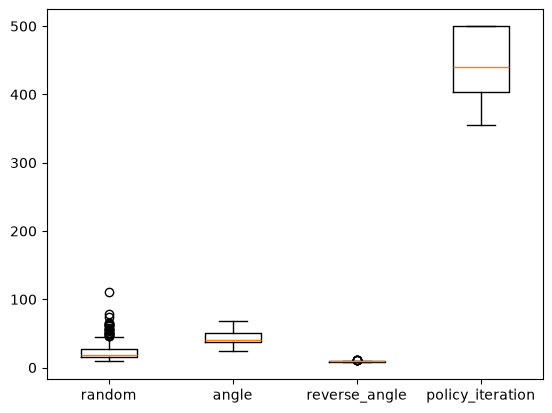

In [26]:
draw_box_plots(records.T, names)

# 4. Value iteration

In [63]:
# def bellman_optimal_pi(v, prob, reward, gamma):
# 	v_new = np.zeros(v.shape[0])
# 	states = np.arange(v.shape[0])
# 	for state in states:
# 		for nxt_state, p in prob[state][action].items():
# 			v_new[state] = max(v_new[state], p * (reward[state, action] + gamma * v[nxt_state] if nxt_state != TERMINATED_STATE else 0))
# 	return v_new

def value_evaluation(num_states, prob, reward, gamma = 0.99, num_steps=10000, tol=1e-4):
	v = np.zeros(num_states)
	for _ in range(num_steps):
		q = look_ahead(v, prob, reward, gamma)
		v_new = q.max(axis=1)
		delta = abs(v - v_new).max()
		if delta <= tol:
			return v, "Convergence"
		v = v_new
	return v, "No convergence"


def value_iteration(num_states, pi, prob, reward, gamma = 0.99, num_steps=10000, tol=1e-4):
	for _ in range(num_steps):
		v, msg = value_evaluation(num_states, prob, reward, gamma, tol=tol)
		q = look_ahead(v, prob, reward, gamma)
		pi_new = greedy_keep_ties(q, pi)

		changed = int((pi != pi_new).sum())
		# print(changed)
		if changed == 0:
		# if max(abs(v - q.max(axis=1))) < tol:
			# print(_)
			return pi, v, "Convergence"
		pi = pi_new
	return pi, v, "No convergence"

In [64]:
pi_value_iteration, v_iteration, msg = value_iteration(NUM_STATES, np.zeros(NUM_STATES, dtype=int), prob, sum_rewards, num_steps=100)
print(pi_value_iteration)
print(pi_value_iteration.shape)
print(msg)

[0 0 0 ... 1 1 1]
(2401,)
Convergence


In [65]:
def value_iteration_policy(policy, cuts):
	return lambda obs, rng: int(policy[get_index(obs, cuts)])

test_policy(value_iteration_policy(pi_value_iteration, CUTS), 3)

Episode finished! Total reward: 402


In [67]:
policies = {
	"random": random_policy,
	"angle": angle_policy,
	"reverse_angle": reverse_angle_policy,
	"policy_iteration": policy_iteration_policy(pi, CUTS),
	"value_iteration": value_iteration_policy(pi_value_iteration, CUTS),
}

records = np.array([evaluate(policy)["returns"] for name, policy in policies.items()])
names = np.array([key for key in policies.keys()])

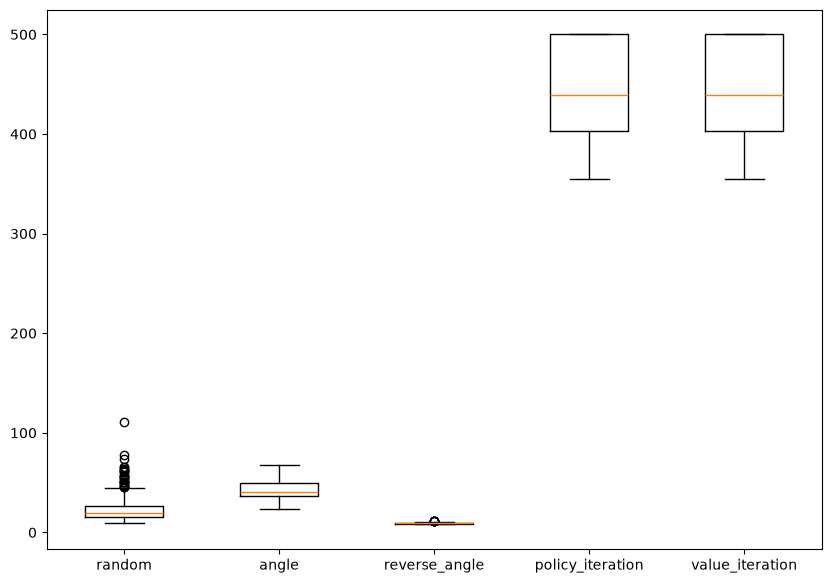

In [72]:
draw_box_plots(records.T, names)